# Validate against buoy observations

Compare **offshore hindcast** (closest goal node), **bulk metamodel**, **spectral metamodel**, and **dynamic SnapWave** to Lauri buoy records.

**Prerequisites**

1. Fitted models — `06_Validate_Metamodel.ipynb` (`mm.fit_all`)
2. Dynamic run for the same period — `08_Dynamic_Cases_Generation.ipynb`
3. Processed buoy pickles under `inputs/LauriBuoys/processed/`

Use the **same `period`** for buoy data, reconstruction, and dynamic output.

Buoy comparisons use **`hs`, `tp`, `dir` only** — observations do not include
directional spread (`spr`). Holdout validation in notebook 06 does score `spr`.

In [1]:
import matplotlib.pyplot as plt
import xarray as xr
from utils.config import SIMULATIONS, resolve
from utils.evaluation import validation as val
from utils.model import metamodel as mm

## Configuration

Map each SnapWave buoy site to a processed pickle. Keys must match mesh site ids
(e.g. `buoy_Apolima_Buoy`). Set `period` to overlap buoy records and dynamic output.

In [2]:
period = "2020"  # e.g. "1990-05" or "2020-05" — must match buoy + dynamic
offshore_name = "WHACS"
mda_n = 450
pca_variance = {"hs": 0.99, "dir": 0.99}

# Buoy sites to validate (subset of buoy_files keys)
sites = ["buoy_Aunuu_Buoy"]

# SnapWave site id → LauriBuoys processed pickle
buoy_files = {
    "buoy_Apolima_Buoy": (
        "inputs/LauriBuoys/processed/samoaapolima_lon187.8_lat-13.88_year1989_1990.pkl"
    ),
    "buoy_Aunuu_Buoy": "inputs/LauriBuoys/processed/americansita.nc",
}

dynamic_path = (
    resolve(SIMULATIONS["dynamic_cases"]) / f"Dynamic_Cases_{offshore_name}_2020.nc"
)

# Buoy pickles may lack direction — compare hs/tp only unless dir is present
variables = ["hs", "tp", "dir"]

print(f"period        : {period}")
print(f"mda_n         : {mda_n}")
print(f"sites         : {sites}")
print(f"dynamic path  : {dynamic_path}")
print(f"dynamic exists: {dynamic_path.is_file()}")

period        : 2020
mda_n         : 450
sites         : ['buoy_Aunuu_Buoy']
dynamic path  : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Dynamic/Dynamic_Cases_WHACS_2020.nc
dynamic exists: True


## 1 · Check models

In [3]:
mm.require_models_all(mda_n, pca_variance=pca_variance)

## 2 · Load buoy observations

In [4]:
# buoy_files_active = {k: buoy_files[k] for k in sites}
# buoy = val.load_buoy_observations(buoy_files_active, time=period)

buoy = (
    xr.open_dataset("inputs/Observations/processed/americansita.nc")
    .rename({"dm": "dir"})
    .sel(time=period)
    .expand_dims({"sites": ["buoy_Aunuu_Buoy"]})
    .transpose("time", "sites")
)
buoy

<xarray.Dataset> Size: 246kB
Dimensions:  (sites: 1, time: 8784)
Coordinates:
  * sites    (sites) object 8B 'buoy_Aunuu_Buoy'
  * time     (time) datetime64[ns] 70kB 2020-01-01 ... 2020-12-31T23:00:00
Data variables:
    hs       (time, sites) float64 70kB 2.323 2.424 2.555 ... 1.622 1.637 1.652
    tp       (time, sites) float32 35kB 9.365 8.679 9.838 ... 8.133 11.76 11.69
    dir      (time, sites) float64 70kB 286.0 305.4 301.6 ... 86.65 80.95 73.14
Attributes:
    standard_name:  sea_surface_wave_significant_height
    units:          m

## 3 · Reconstruct metamodel, load dynamic, and closest-goal offshore hindcast

Metamodel bulk/spectral reconstructions, dynamic SnapWave, and bulk offshore forcing
at each buoy's **closest goal hindcast node** (all sources in ``Samoa.json`` —
currently WHACS only).

In [5]:
bulk = mm.reconstruct(
    period,
    mda_n,
    spectral=False,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

spectral = mm.reconstruct(
    period,
    mda_n,
    spectral=True,
    offshore_name=offshore_name,
    sites=sites,
    pca_variance=pca_variance,
)

if not dynamic_path.is_file():
    raise FileNotFoundError(
        f"Dynamic output not found: {dynamic_path}\n"
        "Run 08_Dynamic_Cases_Generation for this period or change `period`."
    )

dynamic = xr.open_dataset(dynamic_path).sel(time=period)
site_ids = mm.resolve_reconstruction_sites(dynamic, sites)
dynamic = dynamic.sel(sites=site_ids)[[v for v in variables if v in dynamic]].load()

offshore_hindcast, closest_goals = val.load_offshore_hindcast_at_buoys(
    period,
    sites,
    variables=variables,
)
closest_goals

estimates = {
    **offshore_hindcast,
    "Bulk metamodel": bulk[[v for v in variables if v in bulk]],
    "Spectral metamodel": spectral[[v for v in variables if v in spectral]],
    "Dynamic SnapWave": dynamic,
}

2026-07-14 09:34:43,793 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v2__reconstruct__offshore-WHACS__n-450__bulk__goals-all__wl-0__sites-buoy_Aunuu_Buoy__pca-dir0.99_hs0.99__cfg-b6ae470f__time-2020.nc
2026-07-14 09:34:44,114 - hyglow.metamodel - INFO - Loading reconstruction cache: reconstruct-v2__reconstruct__offshore-WHACS__n-450__spectral__goals-all__wl-0__sites-buoy_Aunuu_Buoy__pca-dir0.99_hs0.99__cfg-b6ae470f__time-2020.nc
2026-07-14 09:34:44,802 - hyglow.validation - INFO - Offshore WHACS: 1 site(s) mapped to goals [8]


## 4 · Metrics vs buoy

In [6]:
results = val.compare_all(
    buoy,
    estimates,
    sites=sites,
    variables=variables,
    reference_label="Buoy",
)

summary = val.metrics_summary(results)
summary

2026-07-14 09:34:44,818 - hyglow.validation - INFO - Computed 3 validation metric row(s)
2026-07-14 09:34:44,828 - hyglow.validation - INFO - Computed 3 validation metric row(s)
2026-07-14 09:34:44,838 - hyglow.validation - INFO - Computed 3 validation metric row(s)
2026-07-14 09:34:44,849 - hyglow.validation - INFO - Computed 3 validation metric row(s)


,group,site_source,site_label,variable,label,n,bias,rmse,r2,estimate_label,reference_label,model
0,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.326559,0.395359,0.542766,WHACS (closest goal),Buoy,WHACS (closest goal)
1,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,8784,0.622604,2.431575,0.101940,WHACS (closest goal),Buoy,WHACS (closest goal)
2,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,8784,0.092203,29.058883,0.664388,WHACS (closest goal),Buoy,WHACS (closest goal)
3,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.374584,0.481661,0.252423,Bulk metamodel,Buoy,Bulk metamodel
4,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,8784,0.502219,2.407321,0.091802,Bulk metamodel,Buoy,Bulk metamodel
5,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,8784,3.137140,28.979265,0.666225,Bulk metamodel,Buoy,Bulk metamodel
6,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.310186,0.393152,0.509390,Spectral metamodel,Buoy,Spectral metamodel
7,buoy_Aunuu_Buoy,buoy,waves,tp,Tp,8784,-0.755529,2.121573,0.239663,Spectral metamodel,Buoy,Spectral metamodel
8,buoy_Aunuu_Buoy,buoy,waves,dir,Dir,8784,8.337398,35.229758,0.506714,Spectral metamodel,Buoy,Spectral metamodel
9,buoy_Aunuu_Buoy,buoy,waves,hs,Hs,8784,-0.377367,0.451221,0.332500,Dynamic SnapWave,Buoy,Dynamic SnapWave


## 5 · Scatter plots

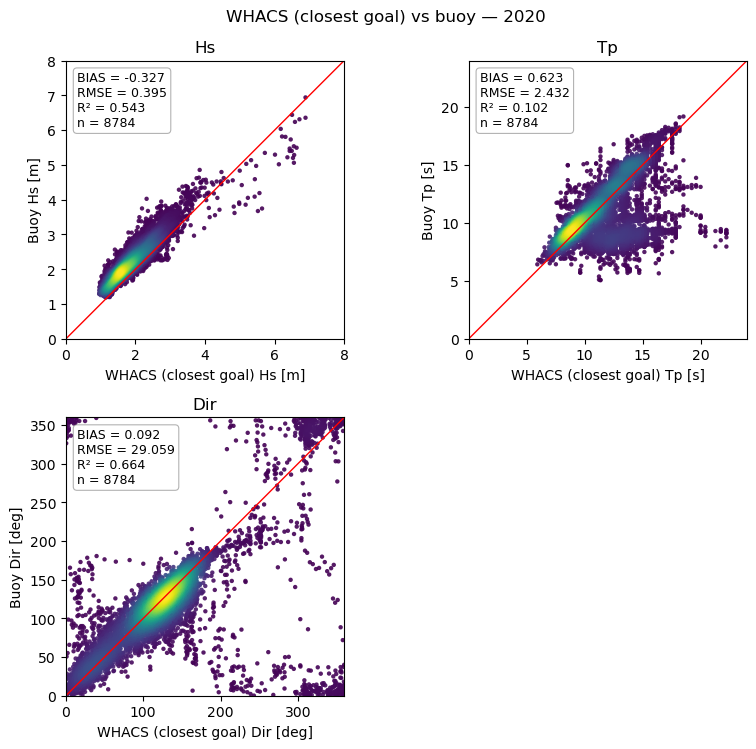

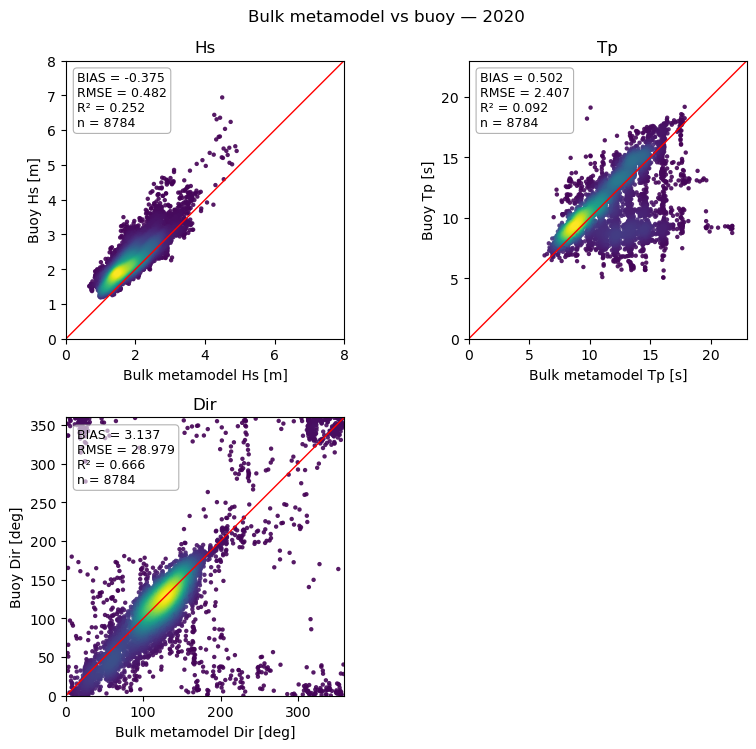

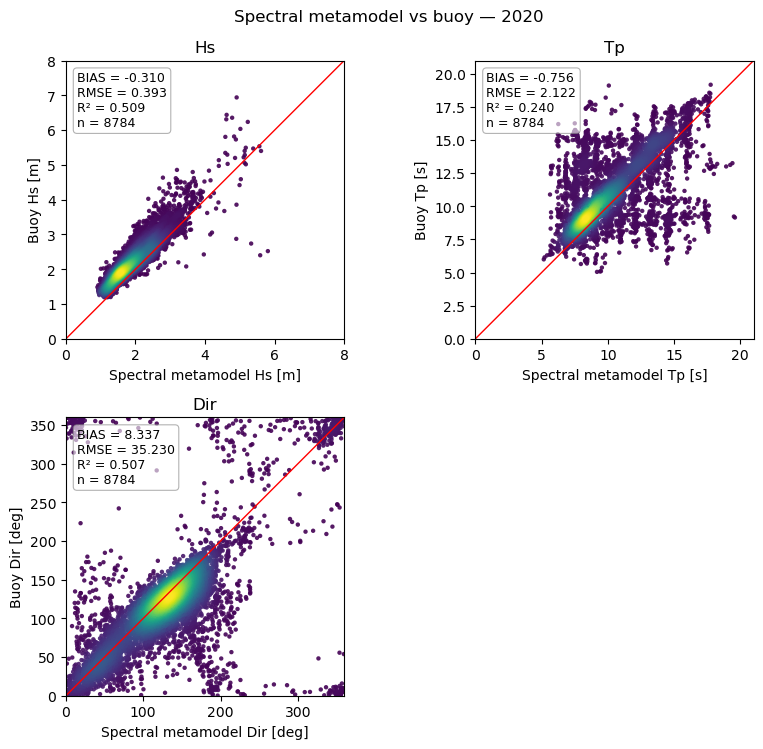

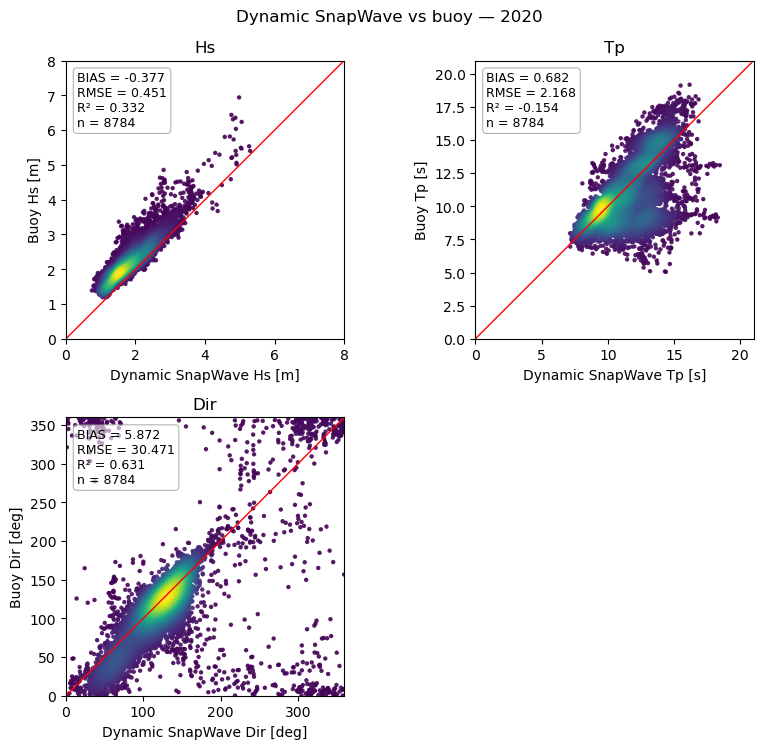

In [7]:
group = mm.resolve_sites(estimates["Bulk metamodel"], sites)[0]

for name, result in results.items():
    result.plot_scatter(
        group,
        variables=variables,
        estimate_label=name,
        reference_label="Buoy",
    )
    plt.suptitle(f"{name} vs buoy — {period}")
    plt.show()

## 6 · Time series

Line plots of buoy observations vs each model over the validation period (direction as scatter).

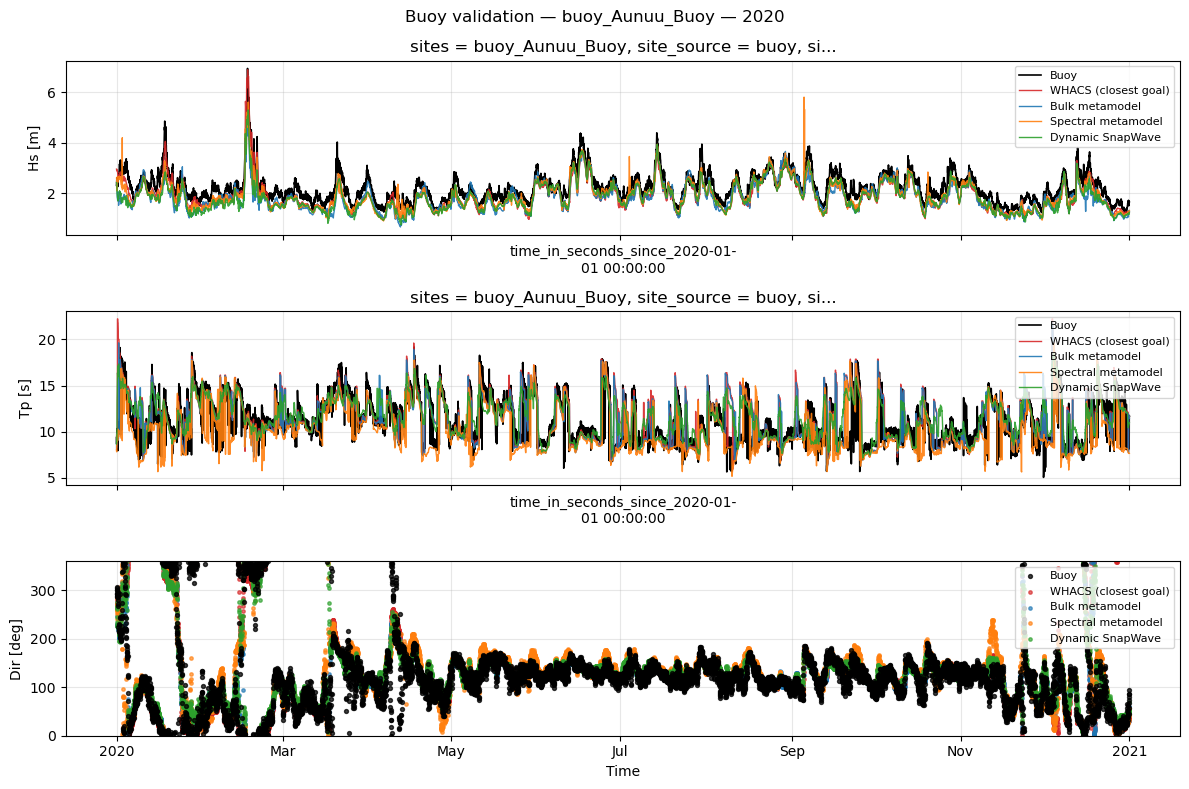

In [8]:
for site in sites:
    val.plot_buoy_timeseries(buoy, estimates, site, variables=variables)
    plt.suptitle(f"Buoy validation — {site} — {period}")
    plt.show()